In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

Classes: ['0_basophil', '1_eosinophil', '2_erythroblast', '3_immature_granulocytes', '4_lymphocyte', '5_monocyte', '6_neutrophil', '7_platelet']
DualBranchNet(
  (local): LocalBranch(
    (gabor): GaborLayer(
      (conv): Conv2d(3, 16, kernel_size=(11, 11), stride=(1, 1), padding=(5, 5), bias=False)
    )
    (features): Sequential(
      (0): ReLU()
      (1): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): AdaptiveAvgPool2d(output_size=(1, 1))
    )
  )
  (global_branch): GlobalAttentionBranch(
    (stage1): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilati

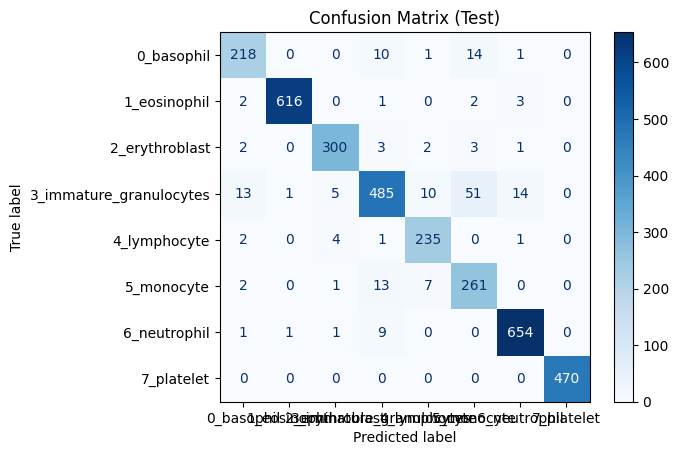

In [2]:
# ============================================================
# Dual-Branch: Gabor CNN + CNN with Shifted Window Attention
# Choquet Fusion (Minkowski Distance)
# BloodMNIST Classification (28x28)
# ============================================================

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 1. Config & Seed
# -------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR = "/kaggle/input/bloodmnist-2828-by-folder"
BATCH_SIZE = 32
IMG_SIZE = 28
EPOCHS = 30
LR = 1e-3
NUM_CLASSES = 8

# -------------------------------------------------------------
# 2. Transforms
# -------------------------------------------------------------
train_transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

val_test_transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

# -------------------------------------------------------------
# 3. Dataset Loading
# -------------------------------------------------------------
train_dir = os.path.join(DATA_DIR, "train")
val_dir   = os.path.join(DATA_DIR, "val")
test_dir  = os.path.join(DATA_DIR, "test")

train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
val_dataset   = datasets.ImageFolder(val_dir, transform=val_test_transform)
test_dataset  = datasets.ImageFolder(test_dir, transform=val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

class_names = train_dataset.classes
print("Classes:", class_names)

# -------------------------------------------------------------
# 4. Gabor Filter Layer
# -------------------------------------------------------------
class GaborLayer(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=11):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size,
                              padding=kernel_size // 2, bias=False)
        self._init_gabor()

    def _init_gabor(self):
        for i in range(self.conv.weight.shape[0]):
            theta = np.random.uniform(0, np.pi)
            sigma = np.random.uniform(2, 5)
            lamda = np.random.uniform(6, 10)
            gamma = 0.5
            kernel = self._gabor_kernel(11, sigma, theta, lamda, gamma)
            for c in range(3):
                self.conv.weight.data[i, c] = torch.tensor(kernel)

    def _gabor_kernel(self, ksize, sigma, theta, lamda, gamma):
        ax = np.linspace(-(ksize // 2), ksize // 2, ksize)
        xx, yy = np.meshgrid(ax, ax)
        x = xx * np.cos(theta) + yy * np.sin(theta)
        y = -xx * np.sin(theta) + yy * np.cos(theta)
        gb = np.exp(-(x**2 + gamma**2 * y**2) / (2 * sigma**2)) \
             * np.cos(2 * np.pi * x / lamda)
        return gb

    def forward(self, x):
        return self.conv(x)

# -------------------------------------------------------------
# 5. Local Branch
# -------------------------------------------------------------
class LocalBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.gabor = GaborLayer(3, 16)

        self.features = nn.Sequential(
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),               # 28 -> 14

            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),               # 14 -> 7

            nn.AdaptiveAvgPool2d((1, 1))
        )

    def forward(self, x):
        x = self.gabor(x)
        x = self.features(x)
        x = x.view(x.size(0), -1)   # [B, 64]
        return x

# -------------------------------------------------------------
# 6. Window Multi-Head Self-Attention (Safe for 14x14 with ws=7)
# -------------------------------------------------------------
class WindowMSA(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4):
        super().__init__()
        self.dim = dim
        self.window_size = window_size
        self.num_heads = num_heads
        self.scale = (dim // num_heads) ** -0.5

        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        # x: [B, H, W, C]
        B, H, W, C = x.shape
        ws = self.window_size

        # H and W must be divisible by ws (14 % 7 == 0 is guaranteed here)
        x = x.view(B, H // ws, ws, W // ws, ws, C)
        x = x.permute(0, 1, 3, 2, 4, 5).contiguous()
        x = x.view(-1, ws * ws, C)  # [num_windows*B, ws*ws, C]

        # Self-attention
        qkv = self.qkv(x).reshape(x.size(0), x.size(1), 3, self.num_heads, C // self.num_heads)
        q, k, v = qkv.unbind(dim=2)

        q = q.transpose(1, 2)
        k = k.transpose(1, 2)
        v = v.transpose(1, 2)

        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)

        out = attn @ v
        out = out.transpose(1, 2).reshape(x.size(0), x.size(1), C)
        out = self.proj(out)

        # Merge windows back
        out = out.view(B, H // ws, W // ws, ws, ws, C)
        out = out.permute(0, 1, 3, 2, 4, 5).contiguous()
        out = out.view(B, H, W, C)

        return out

# -------------------------------------------------------------
# 7. Shifted Window Block (Correct for ws=7, shift=3)
# -------------------------------------------------------------
class ShiftedWindowBlock(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4, shift_size=3):
        super().__init__()
        self.window_size = window_size
        self.shift_size = shift_size

        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowMSA(dim, window_size, num_heads)

        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, x):
        # x: [B, C, H, W]  (H=W=14)
        B, C, H, W = x.shape

        x = x.permute(0, 2, 3, 1)  # [B, H, W, C]

        # Shift
        if self.shift_size > 0:
            x = torch.roll(x, shifts=(-self.shift_size, -self.shift_size), dims=(1, 2))

        # Attention
        x = x + self.attn(self.norm1(x))

        # Reverse shift
        if self.shift_size > 0:
            x = torch.roll(x, shifts=(self.shift_size, self.shift_size), dims=(1, 2))

        # FFN
        x = x + self.mlp(self.norm2(x))

        x = x.permute(0, 3, 1, 2)  # [B, C, H, W]
        return x

# -------------------------------------------------------------
# 8. Global Branch
# -------------------------------------------------------------
class GlobalAttentionBranch(nn.Module):
    def __init__(self):
        super().__init__()

        # Stage 1
        self.stage1 = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)   # 28 -> 14
        )

        # Stage 2
        self.stage2_conv = nn.Conv2d(64, 128, 3, padding=1)

        # Attention blocks on 14x14
        self.attn_block1 = ShiftedWindowBlock(
            dim=128, window_size=7, num_heads=4, shift_size=0
        )

        self.attn_block2 = ShiftedWindowBlock(
            dim=128, window_size=7, num_heads=4, shift_size=3
        )

        # Downsample
        self.pool = nn.MaxPool2d(2)  # 14 -> 7

        # Projection
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.proj = nn.Sequential(
            nn.Linear(128, 256),
            nn.ReLU()
        )

    def forward(self, x):
        x = self.stage1(x)           # [B, 64, 14, 14]
        x = self.stage2_conv(x)     # [B, 128, 14, 14]

        x = self.attn_block1(x)
        x = self.attn_block2(x)

        x = self.pool(x)            # [B, 128, 7, 7]

        x = self.global_pool(x)    # [B, 128, 1, 1]
        x = x.view(x.size(0), -1)  # [B, 128]

        z = self.proj(x)           # [B, 256]
        return z

# -------------------------------------------------------------
# 9. Choquet Fusion
# -------------------------------------------------------------
class ChoquetFusion(nn.Module):
    def __init__(self, dim1, dim2, out_dim=128, p=2):
        super().__init__()
        self.fc1 = nn.Linear(dim1, out_dim)
        self.fc2 = nn.Linear(dim2, out_dim)
        self.p = p

    def forward(self, f1, f2):
        z1 = self.fc1(f1)
        z2 = self.fc2(f2)

        d = torch.pow(torch.abs(z1 - z2), self.p).sum(dim=1, keepdim=True)
        fused = (z1 + z2) / (1.0 + d)
        return fused

# -------------------------------------------------------------
# 10. Dual Branch Network
# -------------------------------------------------------------
class DualBranchNet(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.local = LocalBranch()                 # [B, 64]
        self.global_branch = GlobalAttentionBranch()  # [B, 256]

        self.fusion = ChoquetFusion(64, 256, 128, p=2)
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        f_local = self.local(x)
        f_global = self.global_branch(x)

        fused = self.fusion(f_local, f_global)
        out = self.classifier(fused)
        return out

model = DualBranchNet(num_classes=NUM_CLASSES).to(device)
print(model)

# -------------------------------------------------------------
# 11. Loss & Optimizer
# -------------------------------------------------------------
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

# -------------------------------------------------------------
# 12. Training & Validation Loop
# -------------------------------------------------------------
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(EPOCHS):
    # ---- Train ----
    model.train()
    running_loss = 0.0
    preds_all, labels_all = [], []

    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        preds = torch.argmax(outputs, 1)

        preds_all.extend(preds.cpu().numpy())
        labels_all.extend(labels.cpu().numpy())

    train_loss = running_loss / len(train_loader)
    train_acc = accuracy_score(labels_all, preds_all)

    # ---- Validation ----
    model.eval()
    running_loss = 0.0
    preds_all, labels_all = [], []

    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            preds = torch.argmax(outputs, 1)

            preds_all.extend(preds.cpu().numpy())
            labels_all.extend(labels.cpu().numpy())

    val_loss = running_loss / len(val_loader)
    val_acc = accuracy_score(labels_all, preds_all)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

# -------------------------------------------------------------
# 13. Final Testing
# -------------------------------------------------------------
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        preds = torch.argmax(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)
print("\nFinal Test Accuracy:", test_acc)

print("\nClassification Report (Test):")
print(classification_report(all_labels, all_preds, target_names=class_names))

cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix (Test)")
plt.show()


In [1]:
import os, random, numpy as np, torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, classification_report

# Config
SEED, BATCH_SIZE, EPOCHS, LR, NUM_CLASSES = 42, 32, 30, 1e-3, 8
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = "/kaggle/input/bloodmnist-2828-by-folder"

# Transforms
transform = transforms.Compose([
    transforms.Resize((28, 28)), transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)
])

# Data
train_loader = DataLoader(datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=transform), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(datasets.ImageFolder(os.path.join(DATA_DIR, "test"), transform=transform), batch_size=BATCH_SIZE, shuffle=False)

class GaborLayer(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=11):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, padding=kernel_size // 2, bias=False)
        self._init_gabor()
    def _init_gabor(self):
        for i in range(self.conv.weight.shape[0]):
            theta, sigma, lamda, gamma = np.random.uniform(0, np.pi), np.random.uniform(2, 5), np.random.uniform(6, 10), 0.5
            ax = np.linspace(-(11 // 2), 11 // 2, 11)
            xx, yy = np.meshgrid(ax, ax)
            x = xx * np.cos(theta) + yy * np.sin(theta)
            y = -xx * np.sin(theta) + yy * np.cos(theta)
            kernel = np.exp(-(x**2 + gamma**2 * y**2) / (2 * sigma**2)) * np.cos(2 * np.pi * x / lamda)
            for c in range(3): self.conv.weight.data[i, c] = torch.tensor(kernel)
    def forward(self, x): return self.conv(x)

class GaborOnlyNet(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()
        self.features = nn.Sequential(
            GaborLayer(3, 16), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten()
        )
        self.classifier = nn.Linear(64, num_classes)
    def forward(self, x): return self.classifier(self.features(x))

model = GaborOnlyNet(NUM_CLASSES).to(device)
optimizer = optim.Adam(model.parameters(), lr=LR)
criterion = nn.CrossEntropyLoss()

for epoch in range(EPOCHS):
    model.train()
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad(); loss = criterion(model(imgs), labels); loss.backward(); optimizer.step()
    print(f"Epoch {epoch+1} complete.")

# Test
model.eval(); all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        outputs = model(imgs.to(device))
        all_preds.extend(torch.argmax(outputs, 1).cpu().numpy())
        all_labels.extend(labels.numpy())
print("Gabor Only Accuracy:", accuracy_score(all_labels, all_preds))

Epoch 1 complete.
Epoch 2 complete.
Epoch 3 complete.
Epoch 4 complete.
Epoch 5 complete.
Epoch 6 complete.
Epoch 7 complete.
Epoch 8 complete.
Epoch 9 complete.
Epoch 10 complete.
Epoch 11 complete.
Epoch 12 complete.
Epoch 13 complete.
Epoch 14 complete.
Epoch 15 complete.
Epoch 16 complete.
Epoch 17 complete.
Epoch 18 complete.
Epoch 19 complete.
Epoch 20 complete.
Epoch 21 complete.
Epoch 22 complete.
Epoch 23 complete.
Epoch 24 complete.
Epoch 25 complete.
Epoch 26 complete.
Epoch 27 complete.
Epoch 28 complete.
Epoch 29 complete.
Epoch 30 complete.
Gabor Only Accuracy: 0.9044139140602163


In [2]:
import os, random, numpy as np, torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score

# Config
SEED, BATCH_SIZE, EPOCHS, LR, NUM_CLASSES = 42, 32, 20, 1e-3, 8
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = "/kaggle/input/bloodmnist-2828-by-folder"

# Data Loading
transform = transforms.Compose([transforms.Resize((28, 28)), transforms.ToTensor(), transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)])
train_loader = DataLoader(datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=transform), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(datasets.ImageFolder(os.path.join(DATA_DIR, "val"), transform=transform), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(datasets.ImageFolder(os.path.join(DATA_DIR, "test"), transform=transform), batch_size=BATCH_SIZE, shuffle=False)

class GaborLayer(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=11):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, padding=kernel_size // 2, bias=False)
        self._init_gabor()
    def _init_gabor(self):
        for i in range(self.conv.weight.shape[0]):
            theta, sigma, lamda, gamma = np.random.uniform(0, np.pi), np.random.uniform(2, 5), np.random.uniform(6, 10), 0.5
            ax = np.linspace(-(11 // 2), 11 // 2, 11)
            xx, yy = np.meshgrid(ax, ax)
            x, y = xx * np.cos(theta) + yy * np.sin(theta), -xx * np.sin(theta) + yy * np.cos(theta)
            kernel = np.exp(-(x**2 + gamma**2 * y**2) / (2 * sigma**2)) * np.cos(2 * np.pi * x / lamda)
            for c in range(3): self.conv.weight.data[i, c] = torch.tensor(kernel)
    def forward(self, x): return self.conv(x)

class GaborOnlyNet(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()
        self.feat = nn.Sequential(GaborLayer(3, 16), nn.ReLU(), nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                  nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten())
        self.classifier = nn.Linear(64, num_classes)
    def forward(self, x): return self.classifier(self.feat(x))

model = GaborOnlyNet(NUM_CLASSES).to(device)
optimizer, criterion = optim.Adam(model.parameters(), lr=LR), nn.CrossEntropyLoss()

for epoch in range(EPOCHS):
    model.train(); tr_preds, tr_labels = [], []
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad(); out = model(imgs); loss = criterion(out, labels); loss.backward(); optimizer.step()
        tr_preds.extend(torch.argmax(out, 1).cpu().numpy()); tr_labels.extend(labels.cpu().numpy())
    
    model.eval(); val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, labels in val_loader:
            out = model(imgs.to(device))
            val_preds.extend(torch.argmax(out, 1).cpu().numpy()); val_labels.extend(labels.cpu().numpy())
    print(f"Epoch {epoch+1}: Train Acc: {accuracy_score(tr_labels, tr_preds):.4f} | Val Acc: {accuracy_score(val_labels, val_preds):.4f}")

# Final Test
model.eval(); ts_preds, ts_labels = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        out = model(imgs.to(device)); ts_preds.extend(torch.argmax(out, 1).cpu().numpy()); ts_labels.extend(labels.cpu().numpy())
print(f"\nFinal Test Accuracy: {accuracy_score(ts_labels, ts_preds):.4f}")

Epoch 1: Train Acc: 0.5953 | Val Acc: 0.7091
Epoch 2: Train Acc: 0.7398 | Val Acc: 0.7336
Epoch 3: Train Acc: 0.7695 | Val Acc: 0.7950
Epoch 4: Train Acc: 0.7991 | Val Acc: 0.8388
Epoch 5: Train Acc: 0.8277 | Val Acc: 0.8405
Epoch 6: Train Acc: 0.8365 | Val Acc: 0.8621
Epoch 7: Train Acc: 0.8506 | Val Acc: 0.8417
Epoch 8: Train Acc: 0.8606 | Val Acc: 0.8540
Epoch 9: Train Acc: 0.8649 | Val Acc: 0.8639
Epoch 10: Train Acc: 0.8742 | Val Acc: 0.8779
Epoch 11: Train Acc: 0.8763 | Val Acc: 0.8838
Epoch 12: Train Acc: 0.8887 | Val Acc: 0.8703
Epoch 13: Train Acc: 0.8924 | Val Acc: 0.8808
Epoch 14: Train Acc: 0.8945 | Val Acc: 0.8662
Epoch 15: Train Acc: 0.9005 | Val Acc: 0.8978
Epoch 16: Train Acc: 0.9041 | Val Acc: 0.8843
Epoch 17: Train Acc: 0.9106 | Val Acc: 0.8890
Epoch 18: Train Acc: 0.9094 | Val Acc: 0.8919
Epoch 19: Train Acc: 0.9160 | Val Acc: 0.8919
Epoch 20: Train Acc: 0.9185 | Val Acc: 0.8954

Final Test Accuracy: 0.8901


In [4]:
# (Standard Imports and Helpers as above)
class WindowMSA(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4):
        super().__init__()
        self.dim, self.window_size, self.num_heads = dim, window_size, num_heads
        self.scale = (dim // num_heads) ** -0.5
        self.qkv, self.proj = nn.Linear(dim, dim * 3), nn.Linear(dim, dim)
    def forward(self, x):
        B, H, W, C = x.shape; ws = self.window_size
        x = x.view(B, H // ws, ws, W // ws, ws, C).permute(0, 1, 3, 2, 4, 5).contiguous().view(-1, ws * ws, C)
        qkv = self.qkv(x).reshape(x.size(0), x.size(1), 3, self.num_heads, C // self.num_heads)
        q, k, v = qkv.unbind(dim=2); q, k, v = q.transpose(1, 2), k.transpose(1, 2), v.transpose(1, 2)
        attn = (q @ k.transpose(-2, -1)) * self.scale; attn = attn.softmax(dim=-1)
        out = (attn @ v).transpose(1, 2).reshape(x.size(0), x.size(1), C)
        out = self.proj(out).view(B, H // ws, W // ws, ws, ws, C).permute(0, 1, 3, 2, 4, 5).contiguous().view(B, H, W, C)
        return out

class ShiftedWindowBlock(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4, shift_size=3):
        super().__init__()
        self.window_size, self.shift_size = window_size, shift_size
        self.norm1, self.attn = nn.LayerNorm(dim), WindowMSA(dim, window_size, num_heads)
        self.norm2, self.mlp = nn.LayerNorm(dim), nn.Sequential(nn.Linear(dim, dim * 4), nn.GELU(), nn.Linear(dim * 4, dim))
    def forward(self, x):
        B, C, H, W = x.shape; x = x.permute(0, 2, 3, 1)
        if self.shift_size > 0: x = torch.roll(x, shifts=(-self.shift_size, -self.shift_size), dims=(1, 2))
        x = x + self.attn(self.norm1(x))
        if self.shift_size > 0: x = torch.roll(x, shifts=(self.shift_size, self.shift_size), dims=(1, 2))
        x = x + self.mlp(self.norm2(x))
        return x.permute(0, 3, 1, 2)

class SWMHSAOnlyNet(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(3, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(64, 128, 3, padding=1),
                                 ShiftedWindowBlock(128, 7, 4, 0), ShiftedWindowBlock(128, 7, 4, 3), nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten())
        self.classifier = nn.Linear(128, num_classes)
    def forward(self, x): return self.classifier(self.net(x))

model = SWMHSAOnlyNet(NUM_CLASSES).to(device)
optimizer, criterion = optim.Adam(model.parameters(), lr=LR), nn.CrossEntropyLoss()

for epoch in range(EPOCHS):
    model.train(); tr_preds, tr_labels = [], []
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad(); out = model(imgs); loss = criterion(out, labels); loss.backward(); optimizer.step()
        tr_preds.extend(torch.argmax(out, 1).cpu().numpy()); tr_labels.extend(labels.cpu().numpy())
    
    model.eval(); val_preds, val_labels = [], []
    with torch.no_grad():
        for imgs, labels in val_loader:
            out = model(imgs.to(device))
            val_preds.extend(torch.argmax(out, 1).cpu().numpy()); val_labels.extend(labels.cpu().numpy())
    print(f"Epoch {epoch+1}: Train Acc: {accuracy_score(tr_labels, tr_preds):.4f} | Val Acc: {accuracy_score(val_labels, val_preds):.4f}")

# Final Test
model.eval(); ts_preds, ts_labels = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        out = model(imgs.to(device)); ts_preds.extend(torch.argmax(out, 1).cpu().numpy()); ts_labels.extend(labels.cpu().numpy())
print(f"\nFinal Test Accuracy: {accuracy_score(ts_labels, ts_preds):.4f}")

Epoch 1: Train Acc: 0.7417 | Val Acc: 0.8475
Epoch 2: Train Acc: 0.8475 | Val Acc: 0.8902
Epoch 3: Train Acc: 0.8804 | Val Acc: 0.8914
Epoch 4: Train Acc: 0.9034 | Val Acc: 0.9141
Epoch 5: Train Acc: 0.9104 | Val Acc: 0.9334
Epoch 6: Train Acc: 0.9194 | Val Acc: 0.9293
Epoch 7: Train Acc: 0.9236 | Val Acc: 0.9451
Epoch 8: Train Acc: 0.9280 | Val Acc: 0.9463
Epoch 9: Train Acc: 0.9288 | Val Acc: 0.9398
Epoch 10: Train Acc: 0.9401 | Val Acc: 0.9340
Epoch 11: Train Acc: 0.9415 | Val Acc: 0.9416
Epoch 12: Train Acc: 0.9453 | Val Acc: 0.9457
Epoch 13: Train Acc: 0.9442 | Val Acc: 0.9153
Epoch 14: Train Acc: 0.9497 | Val Acc: 0.9363
Epoch 15: Train Acc: 0.9499 | Val Acc: 0.9433
Epoch 16: Train Acc: 0.9553 | Val Acc: 0.9246
Epoch 17: Train Acc: 0.9479 | Val Acc: 0.9451
Epoch 18: Train Acc: 0.9593 | Val Acc: 0.9334
Epoch 19: Train Acc: 0.9548 | Val Acc: 0.9439
Epoch 20: Train Acc: 0.9565 | Val Acc: 0.9422

Final Test Accuracy: 0.9372


In [3]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score

# -------------------------------------------------------------
# 1. Global Configuration
# -------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = "/kaggle/input/bloodmnist-2828-by-folder"  # Adjust as per your environment
BATCH_SIZE = 32
EPOCHS = 20
LR = 1e-3
NUM_CLASSES = 8

# -------------------------------------------------------------
# 2. Data Pipeline
# -------------------------------------------------------------
train_transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

test_transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# Ensure paths exist before loading
train_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=train_transform)
val_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, "val"), transform=test_transform)
test_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, "test"), transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# -------------------------------------------------------------
# 3. Model Components (Local & Global)
# -------------------------------------------------------------
class GaborLayer(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=11):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, padding=kernel_size//2, bias=False)
        self._init_gabor()

    def _init_gabor(self):
        for i in range(self.conv.weight.shape[0]):
            theta, sigma, lamda, gamma = np.random.uniform(0, np.pi), np.random.uniform(2, 5), \
                                         np.random.uniform(6, 10), 0.5
            ax = np.linspace(-(11//2), 11//2, 11)
            xx, yy = np.meshgrid(ax, ax)
            x = xx * np.cos(theta) + yy * np.sin(theta)
            y = -xx * np.sin(theta) + yy * np.cos(theta)
            gb = np.exp(-(x**2 + gamma**2 * y**2) / (2 * sigma**2)) * np.cos(2 * np.pi * x / lamda)
            for c in range(3): self.conv.weight.data[i, c] = torch.tensor(gb)

    def forward(self, x): return self.conv(x)

class LocalBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            GaborLayer(3, 16), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten()
        )
    def forward(self, x): return self.net(x)

class WindowMSA(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4):
        super().__init__()
        self.dim, self.ws, self.nh = dim, window_size, num_heads
        self.scale = (dim // num_heads) ** -0.5
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        B, H, W, C = x.shape
        x = x.view(B, H // self.ws, self.ws, W // self.ws, self.ws, C).permute(0, 1, 3, 2, 4, 5).reshape(-1, self.ws*self.ws, C)
        qkv = self.qkv(x).reshape(x.shape[0], x.shape[1], 3, self.nh, C // self.nh).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        out = (attn @ v).transpose(1, 2).reshape(-1, self.ws*self.ws, C)
        out = self.proj(out).view(B, H // self.ws, W // self.ws, self.ws, self.ws, C).permute(0, 1, 3, 2, 4, 5).reshape(B, H, W, C)
        return out

class ShiftedWindowBlock(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4, shift_size=0):
        super().__init__()
        self.shift = shift_size
        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowMSA(dim, window_size, num_heads)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, dim*4), nn.GELU(), nn.Linear(dim*4, dim))

    def forward(self, x):
        x = x.permute(0, 2, 3, 1)
        if self.shift > 0: x = torch.roll(x, shifts=(-self.shift, -self.shift), dims=(1, 2))
        x = x + self.attn(self.norm1(x))
        if self.shift > 0: x = torch.roll(x, shifts=(self.shift, self.shift), dims=(1, 2))
        x = x + self.mlp(self.norm2(x))
        return x.permute(0, 3, 1, 2)

class GlobalBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.stage1 = nn.Sequential(nn.Conv2d(3, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.stage2 = nn.Conv2d(64, 128, 3, padding=1)
        self.attn = nn.Sequential(
            ShiftedWindowBlock(128, 7, 4, 0),
            ShiftedWindowBlock(128, 7, 4, 3)
        )
        self.head = nn.Sequential(nn.MaxPool2d(2), nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(), nn.Linear(128, 256), nn.ReLU())
    def forward(self, x): return self.head(self.attn(self.stage2(self.stage1(x))))

# -------------------------------------------------------------
# 4. Fusion Strategies
# -------------------------------------------------------------
class BaseFusion(nn.Module):
    def __init__(self, d1=64, d2=256, d_out=128):
        super().__init__()
        self.p1 = nn.Linear(d1, d_out)
        self.p2 = nn.Linear(d2, d_out)

class ConcatFusion(BaseFusion):
    def forward(self, f1, f2):
        return torch.cat([self.p1(f1), self.p2(f2)], dim=1)

class WeightedAvgFusion(BaseFusion):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.w = nn.Parameter(torch.ones(2))
    def forward(self, f1, f2):
        weights = torch.softmax(self.w, dim=0)
        return weights[0] * self.p1(f1) + weights[1] * self.p2(f2)

class ParsevalFusion(BaseFusion):
    def forward(self, f1, f2):
        z1, z2 = self.p1(f1), self.p2(f2)
        eps = 1e-8
        z1_n2, z2_n2 = torch.sum(z1**2, dim=1), torch.sum(z2**2, dim=1)
        eta = (2 * torch.sum(z1 * z2, dim=1)) / (z1_n2 + z2_n2 + eps)
        A = (1 + eta) / 2
        return A.unsqueeze(1) * (z1 + z2)

class FullChoquetFusion(BaseFusion):
    def forward(self, f1, f2):
        z1, z2 = self.p1(f1), self.p2(f2)
        eps = 1e-8
        # Minkowski d3: geometric divergence
        d3 = torch.pow(torch.sum(torch.abs(z1 - z2)**3, dim=1), 1/3)
        alpha = 1 / (1 + d3 + eps)
        # Parseval eta: alignment uncertainty
        z1_n2, z2_n2 = torch.sum(z1**2, dim=1), torch.sum(z2**2, dim=1)
        eta = (2 * torch.sum(z1 * z2, dim=1)) / (z1_n2 + z2_n2 + eps)
        A = (1 + eta) / 2
        # Final Operator: A * alpha * (z1 + z2)
        return (A * alpha).unsqueeze(1) * (z1 + z2)

# -------------------------------------------------------------
# 5. Dual Branch Master Architecture
# -------------------------------------------------------------
class DualBranchNet(nn.Module):
    def __init__(self, fusion_type='choquet'):
        super().__init__()
        self.local = LocalBranch()
        self.global_b = GlobalBranch()
        
        f_map = {
            'concat': (ConcatFusion, 256),
            'weight': (WeightedAvgFusion, 128),
            'parseval': (ParsevalFusion, 128),
            'choquet': (FullChoquetFusion, 128)
        }
        f_cls, class_in = f_map[fusion_type]
        self.fusion = f_cls()
        self.classifier = nn.Linear(class_in, NUM_CLASSES)

    def forward(self, x):
        f_l, f_g = self.local(x), self.global_b(x)
        fused = self.fusion(f_l, f_g)
        return self.classifier(fused)

# -------------------------------------------------------------
# 6. Training & Evaluation Engine
# -------------------------------------------------------------
def run_full_pipeline(variant):
    print(f"\n>>> Running Variant: {variant.upper()}")
    model = DualBranchNet(fusion_type=variant).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(1, EPOCHS + 1):
        # Train
        model.train()
        train_preds, train_labels = [], []
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            train_preds.extend(torch.argmax(outputs, 1).cpu().numpy())
            train_labels.extend(labels.cpu().numpy())
        
        t_acc = accuracy_score(train_labels, train_preds)

        # Validation
        model.eval()
        val_preds, val_labels = [], []
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                val_preds.extend(torch.argmax(outputs, 1).cpu().numpy())
                val_labels.extend(labels.cpu().numpy())
        
        v_acc = accuracy_score(val_labels, val_preds)
        print(f"Epoch [{epoch:02d}/{EPOCHS}] | Train Acc: {t_acc:.4f} | Val Acc: {v_acc:.4f}")

    # Final Test
    test_preds, test_labels = [], []
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            outputs = model(imgs)
            test_preds.extend(torch.argmax(outputs, 1).cpu().numpy())
            test_labels.extend(labels.cpu().numpy())
    
    final_test_acc = accuracy_score(test_labels, test_preds)
    print(f"--- Final Test Accuracy for {variant.upper()}: {final_test_acc:.4f} ---")
    return final_test_acc

# -------------------------------------------------------------
# 7. Main Execution
# -------------------------------------------------------------
if __name__ == "__main__":
    variants = ['concat', 'weight', 'parseval', 'choquet']
    summary_results = {}
    
    for v in variants:
        summary_results[v] = run_full_pipeline(v)

    print("\n" + "="*30)
    print("FINAL SUMMARY COMPARISON")
    print("="*30)
    for v, acc in summary_results.items():
        print(f"{v.capitalize():<10}: {acc:.4f}")


>>> Running Variant: CONCAT
Epoch [01/20] | Train Acc: 0.6970 | Val Acc: 0.8318
Epoch [02/20] | Train Acc: 0.8248 | Val Acc: 0.8487
Epoch [03/20] | Train Acc: 0.8423 | Val Acc: 0.8657
Epoch [04/20] | Train Acc: 0.8772 | Val Acc: 0.8803
Epoch [05/20] | Train Acc: 0.8795 | Val Acc: 0.9136
Epoch [06/20] | Train Acc: 0.9007 | Val Acc: 0.9083
Epoch [07/20] | Train Acc: 0.9114 | Val Acc: 0.9258
Epoch [08/20] | Train Acc: 0.9178 | Val Acc: 0.9352
Epoch [09/20] | Train Acc: 0.9242 | Val Acc: 0.9311
Epoch [10/20] | Train Acc: 0.9304 | Val Acc: 0.9077
Epoch [11/20] | Train Acc: 0.9323 | Val Acc: 0.9381
Epoch [12/20] | Train Acc: 0.9405 | Val Acc: 0.9211
Epoch [13/20] | Train Acc: 0.9385 | Val Acc: 0.9533
Epoch [14/20] | Train Acc: 0.9386 | Val Acc: 0.9521
Epoch [15/20] | Train Acc: 0.9421 | Val Acc: 0.9375
Epoch [16/20] | Train Acc: 0.9465 | Val Acc: 0.9188
Epoch [17/20] | Train Acc: 0.9480 | Val Acc: 0.9527
Epoch [18/20] | Train Acc: 0.9476 | Val Acc: 0.9533
Epoch [19/20] | Train Acc: 0.9485 |

Classes: ['0_basophil', '1_eosinophil', '2_erythroblast', '3_immature_granulocytes', '4_lymphocyte', '5_monocyte', '6_neutrophil', '7_platelet']
DualBranchNet(
  (local): LocalBranch(
    (gabor): GaborLayer(
      (conv): Conv2d(3, 16, kernel_size=(11, 11), stride=(1, 1), padding=(5, 5), bias=False)
    )
    (features): Sequential(
      (0): ReLU()
      (1): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): AdaptiveAvgPool2d(output_size=(1, 1))
    )
  )
  (global_branch): GlobalAttentionBranch(
    (stage1): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilati

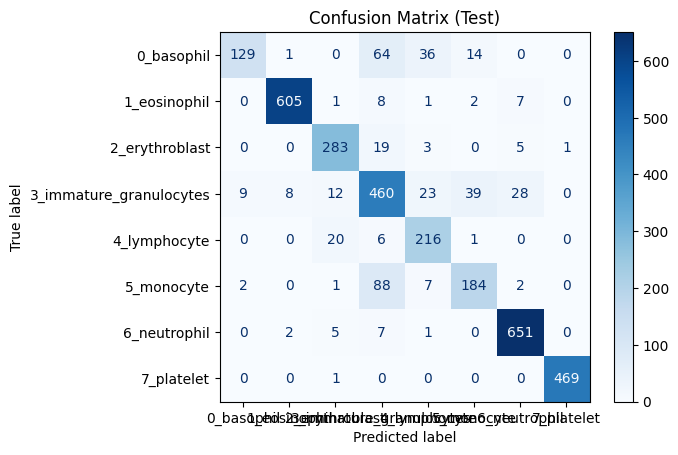

In [1]:
# ============================================================
# Dual-Branch: Gabor CNN + CNN with Shifted Window Attention
# Choquet Fusion (Minkowski Distance)
# BloodMNIST Classification (28x28)
# ============================================================

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 1. Config & Seed
# -------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR = "/kaggle/input/bloodmnist-2828-by-folder"
BATCH_SIZE = 32
IMG_SIZE = 28
EPOCHS = 5
LR = 1e-3
NUM_CLASSES = 8

# -------------------------------------------------------------
# 2. Transforms
# -------------------------------------------------------------
train_transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

val_test_transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

# -------------------------------------------------------------
# 3. Dataset Loading
# -------------------------------------------------------------
train_dir = os.path.join(DATA_DIR, "train")
val_dir   = os.path.join(DATA_DIR, "val")
test_dir  = os.path.join(DATA_DIR, "test")

train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
val_dataset   = datasets.ImageFolder(val_dir, transform=val_test_transform)
test_dataset  = datasets.ImageFolder(test_dir, transform=val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

class_names = train_dataset.classes
print("Classes:", class_names)

# -------------------------------------------------------------
# 4. Gabor Filter Layer
# -------------------------------------------------------------
class GaborLayer(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=11):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size,
                              padding=kernel_size // 2, bias=False)
        self._init_gabor()

    def _init_gabor(self):
        for i in range(self.conv.weight.shape[0]):
            theta = np.random.uniform(0, np.pi)
            sigma = np.random.uniform(2, 5)
            lamda = np.random.uniform(6, 10)
            gamma = 0.5
            kernel = self._gabor_kernel(11, sigma, theta, lamda, gamma)
            for c in range(3):
                self.conv.weight.data[i, c] = torch.tensor(kernel)

    def _gabor_kernel(self, ksize, sigma, theta, lamda, gamma):
        ax = np.linspace(-(ksize // 2), ksize // 2, ksize)
        xx, yy = np.meshgrid(ax, ax)
        x = xx * np.cos(theta) + yy * np.sin(theta)
        y = -xx * np.sin(theta) + yy * np.cos(theta)
        gb = np.exp(-(x**2 + gamma**2 * y**2) / (2 * sigma**2)) \
             * np.cos(2 * np.pi * x / lamda)
        return gb

    def forward(self, x):
        return self.conv(x)

# -------------------------------------------------------------
# 5. Local Branch
# -------------------------------------------------------------
class LocalBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.gabor = GaborLayer(3, 16)

        self.features = nn.Sequential(
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),               # 28 -> 14

            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),               # 14 -> 7

            nn.AdaptiveAvgPool2d((1, 1))
        )

    def forward(self, x):
        x = self.gabor(x)
        x = self.features(x)
        x = x.view(x.size(0), -1)   # [B, 64]
        return x

# -------------------------------------------------------------
# 6. Window Multi-Head Self-Attention (Safe for 14x14 with ws=7)
# -------------------------------------------------------------
class WindowMSA(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4):
        super().__init__()
        self.dim = dim
        self.window_size = window_size
        self.num_heads = num_heads
        self.scale = (dim // num_heads) ** -0.5

        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        # x: [B, H, W, C]
        B, H, W, C = x.shape
        ws = self.window_size

        # H and W must be divisible by ws (14 % 7 == 0 is guaranteed here)
        x = x.view(B, H // ws, ws, W // ws, ws, C)
        x = x.permute(0, 1, 3, 2, 4, 5).contiguous()
        x = x.view(-1, ws * ws, C)  # [num_windows*B, ws*ws, C]

        # Self-attention
        qkv = self.qkv(x).reshape(x.size(0), x.size(1), 3, self.num_heads, C // self.num_heads)
        q, k, v = qkv.unbind(dim=2)

        q = q.transpose(1, 2)
        k = k.transpose(1, 2)
        v = v.transpose(1, 2)

        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)

        out = attn @ v
        out = out.transpose(1, 2).reshape(x.size(0), x.size(1), C)
        out = self.proj(out)

        # Merge windows back
        out = out.view(B, H // ws, W // ws, ws, ws, C)
        out = out.permute(0, 1, 3, 2, 4, 5).contiguous()
        out = out.view(B, H, W, C)

        return out

# -------------------------------------------------------------
# 7. Shifted Window Block (Correct for ws=7, shift=3)
# -------------------------------------------------------------
class ShiftedWindowBlock(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4, shift_size=3):
        super().__init__()
        self.window_size = window_size
        self.shift_size = shift_size

        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowMSA(dim, window_size, num_heads)

        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, x):
        # x: [B, C, H, W]  (H=W=14)
        B, C, H, W = x.shape

        x = x.permute(0, 2, 3, 1)  # [B, H, W, C]

        # Shift
        if self.shift_size > 0:
            x = torch.roll(x, shifts=(-self.shift_size, -self.shift_size), dims=(1, 2))

        # Attention
        x = x + self.attn(self.norm1(x))

        # Reverse shift
        if self.shift_size > 0:
            x = torch.roll(x, shifts=(self.shift_size, self.shift_size), dims=(1, 2))

        # FFN
        x = x + self.mlp(self.norm2(x))

        x = x.permute(0, 3, 1, 2)  # [B, C, H, W]
        return x

# -------------------------------------------------------------
# 8. Global Branch
# -------------------------------------------------------------
class GlobalAttentionBranch(nn.Module):
    def __init__(self):
        super().__init__()

        # Stage 1
        self.stage1 = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)   # 28 -> 14
        )

        # Stage 2
        self.stage2_conv = nn.Conv2d(64, 128, 3, padding=1)

        # Attention blocks on 14x14
        self.attn_block1 = ShiftedWindowBlock(
            dim=128, window_size=7, num_heads=4, shift_size=0
        )

        self.attn_block2 = ShiftedWindowBlock(
            dim=128, window_size=7, num_heads=4, shift_size=3
        )

        # Downsample
        self.pool = nn.MaxPool2d(2)  # 14 -> 7

        # Projection
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.proj = nn.Sequential(
            nn.Linear(128, 256),
            nn.ReLU()
        )

    def forward(self, x):
        x = self.stage1(x)           # [B, 64, 14, 14]
        x = self.stage2_conv(x)     # [B, 128, 14, 14]

        x = self.attn_block1(x)
        x = self.attn_block2(x)

        x = self.pool(x)            # [B, 128, 7, 7]

        x = self.global_pool(x)    # [B, 128, 1, 1]
        x = x.view(x.size(0), -1)  # [B, 128]

        z = self.proj(x)           # [B, 256]
        return z

# -------------------------------------------------------------
# 9. Choquet Fusion
# -------------------------------------------------------------
class ChoquetFusion(nn.Module):
    def __init__(self, dim1, dim2, out_dim=128, p=2):
        super().__init__()
        self.fc1 = nn.Linear(dim1, out_dim)
        self.fc2 = nn.Linear(dim2, out_dim)
        self.p = p

    def forward(self, f1, f2):
        z1 = self.fc1(f1)
        z2 = self.fc2(f2)

        d = torch.pow(torch.abs(z1 - z2), self.p).sum(dim=1, keepdim=True)
        fused = (z1 + z2) / (1.0 + d)
        return fused

# -------------------------------------------------------------
# 10. Dual Branch Network
# -------------------------------------------------------------
class DualBranchNet(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.local = LocalBranch()                 # [B, 64]
        self.global_branch = GlobalAttentionBranch()  # [B, 256]

        self.fusion = ChoquetFusion(64, 256, 128, p=2)
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        f_local = self.local(x)
        f_global = self.global_branch(x)

        fused = self.fusion(f_local, f_global)
        out = self.classifier(fused)
        return out

model = DualBranchNet(num_classes=NUM_CLASSES).to(device)
print(model)

# -------------------------------------------------------------
# 11. Loss & Optimizer
# -------------------------------------------------------------
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

# -------------------------------------------------------------
# 12. Training & Validation Loop
# -------------------------------------------------------------
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(EPOCHS):
    # ---- Train ----
    model.train()
    running_loss = 0.0
    preds_all, labels_all = [], []

    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        preds = torch.argmax(outputs, 1)

        preds_all.extend(preds.cpu().numpy())
        labels_all.extend(labels.cpu().numpy())

    train_loss = running_loss / len(train_loader)
    train_acc = accuracy_score(labels_all, preds_all)

    # ---- Validation ----
    model.eval()
    running_loss = 0.0
    preds_all, labels_all = [], []

    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            preds = torch.argmax(outputs, 1)

            preds_all.extend(preds.cpu().numpy())
            labels_all.extend(labels.cpu().numpy())

    val_loss = running_loss / len(val_loader)
    val_acc = accuracy_score(labels_all, preds_all)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

# -------------------------------------------------------------
# 13. Final Testing
# -------------------------------------------------------------
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        preds = torch.argmax(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)
print("\nFinal Test Accuracy:", test_acc)

print("\nClassification Report (Test):")
print(classification_report(all_labels, all_preds, target_names=class_names))

cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix (Test)")
plt.show()


[*] Extracting features ...
    Local  : (3421, 64)
    Global : (3421, 256)
    Fused  : (3421, 128)
  Running t-SNE: Local Branch
(Gabor-CNN, dim=64) ...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


  Running t-SNE: Global Branch
(Shifted-Window Attn, dim=256) ...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


  Running t-SNE: Fused Features
(Choquet Fusion, dim=128) ...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


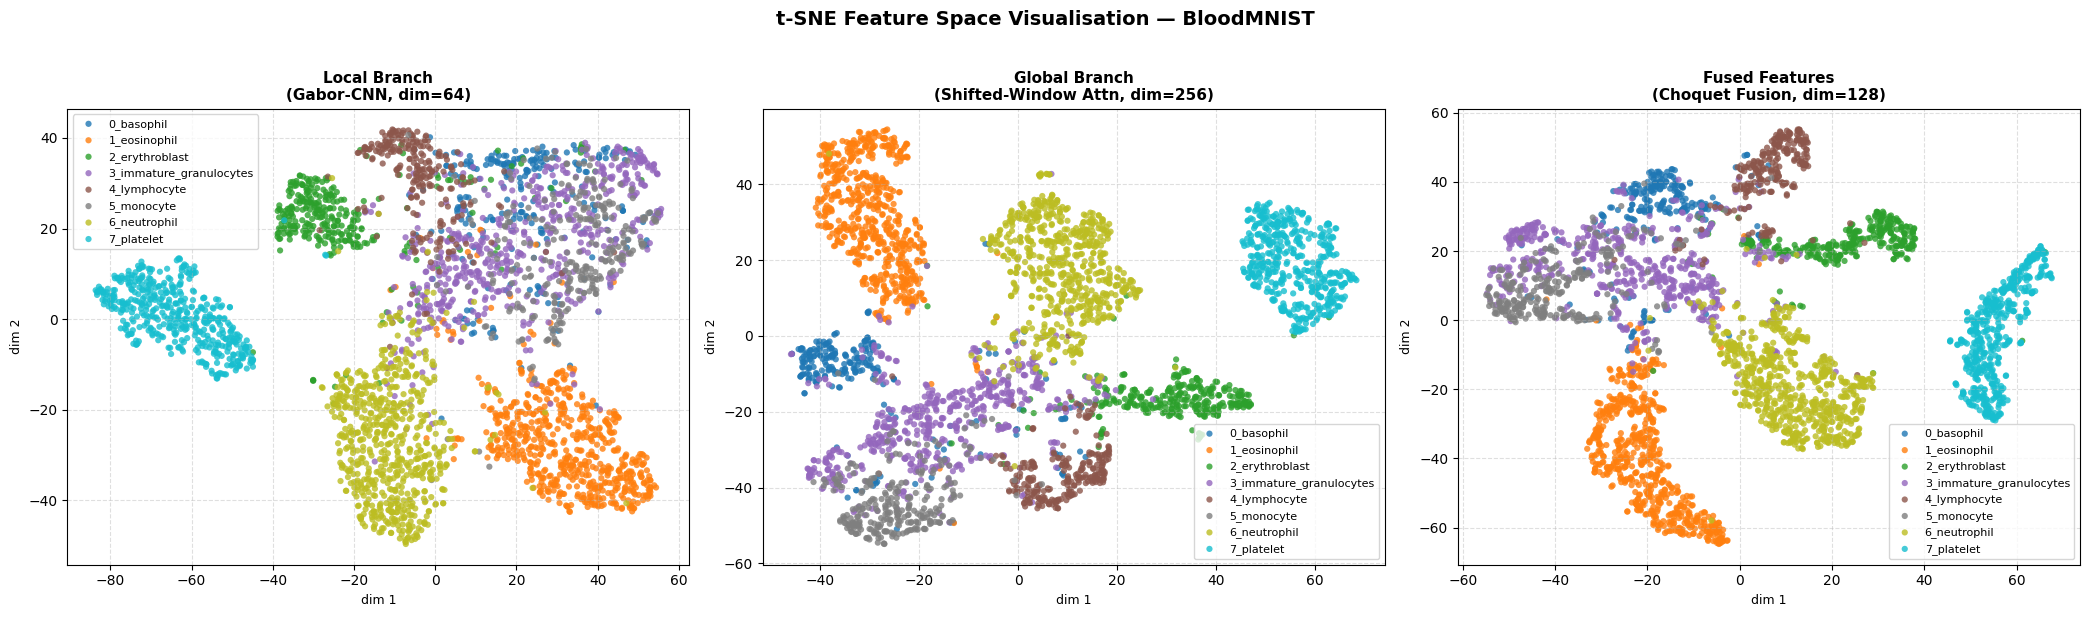

[✓] Saved → /kaggle/working/tsne_all_branches.png


In [2]:
# ============================================================
# t-SNE Plots: Local, Global, and Fused Branch Features
# Run this AFTER your training cell
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import torch

SEED = 42

# =============================================================
# STEP 1 — Extract Features from All Three Branches
# =============================================================

def extract_features(model, loader, device):
    model.eval()

    local_feats  = []
    global_feats = []
    fused_feats  = []
    all_labels   = []

    fused_buffer = []
    def fused_hook(module, input, output):
        fused_buffer.append(output.detach().cpu().numpy())

    handle = model.fusion.register_forward_hook(fused_hook)

    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)

            lf = model.local(imgs).cpu().numpy()           # [B, 64]
            gf = model.global_branch(imgs).cpu().numpy()   # [B, 256]

            local_feats.append(lf)
            global_feats.append(gf)
            all_labels.extend(labels.numpy())

            _ = model(imgs)   # triggers fusion hook

    handle.remove()

    return (
        np.vstack(local_feats),
        np.vstack(global_feats),
        np.vstack(fused_buffer),
        np.array(all_labels)
    )


# =============================================================
# STEP 2 — Plot t-SNE
# =============================================================

def plot_tsne(features, labels, class_names, title, ax, perplexity=30):
    print(f"  Running t-SNE: {title} ...")
    tsne = TSNE(n_components=2, perplexity=perplexity,
                n_iter=1000, random_state=SEED)
    emb  = tsne.fit_transform(features)

    colors = plt.cm.tab10(np.linspace(0, 1, len(class_names)))
    for idx, (cls_name, color) in enumerate(zip(class_names, colors)):
        mask = labels == idx
        ax.scatter(emb[mask, 0], emb[mask, 1],
                   label=cls_name, color=color,
                   s=20, alpha=0.8, edgecolors='none')

    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel("dim 1", fontsize=9)
    ax.set_ylabel("dim 2", fontsize=9)
    ax.legend(fontsize=8, loc='best')
    ax.grid(True, linestyle='--', alpha=0.4)


# =============================================================
# STEP 3 — Run Everything
# =============================================================

print("[*] Extracting features ...")
local_f, global_f, fused_f, labels = extract_features(model, test_loader, device)
print(f"    Local  : {local_f.shape}")   # (N, 64)
print(f"    Global : {global_f.shape}")  # (N, 256)
print(f"    Fused  : {fused_f.shape}")   # (N, 128)

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
fig.suptitle("t-SNE Feature Space Visualisation — BloodMNIST",
             fontsize=14, fontweight='bold', y=1.02)

plot_tsne(local_f,  labels, class_names, "Local Branch\n(Gabor-CNN, dim=64)",              axes[0])
plot_tsne(global_f, labels, class_names, "Global Branch\n(Shifted-Window Attn, dim=256)",  axes[1])
plot_tsne(fused_f,  labels, class_names, "Fused Features\n(Choquet Fusion, dim=128)",      axes[2])

plt.tight_layout()
plt.savefig("/kaggle/working/tsne_all_branches.png", dpi=150, bbox_inches='tight')
plt.show()
print("[✓] Saved → /kaggle/working/tsne_all_branches.png")

In [3]:
from IPython.display import FileLink
FileLink('/kaggle/working/tsne_all_branches.png')

/kaggle/working/tsne_all_branches.png

  Running t-SNE: Local Branch
(Gabor-CNN, dim=64) ...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


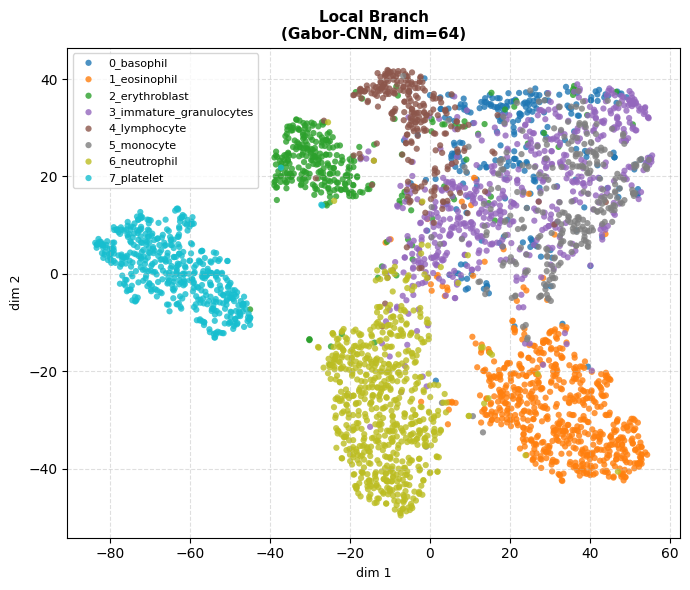

  Running t-SNE: Global Branch
(Shifted-Window Attn, dim=256) ...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


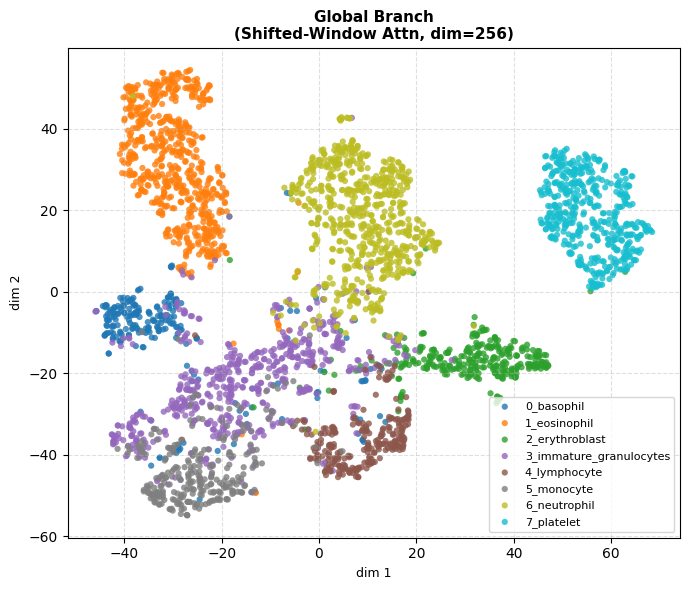

  Running t-SNE: Fused Features
(Choquet Fusion, dim=128) ...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


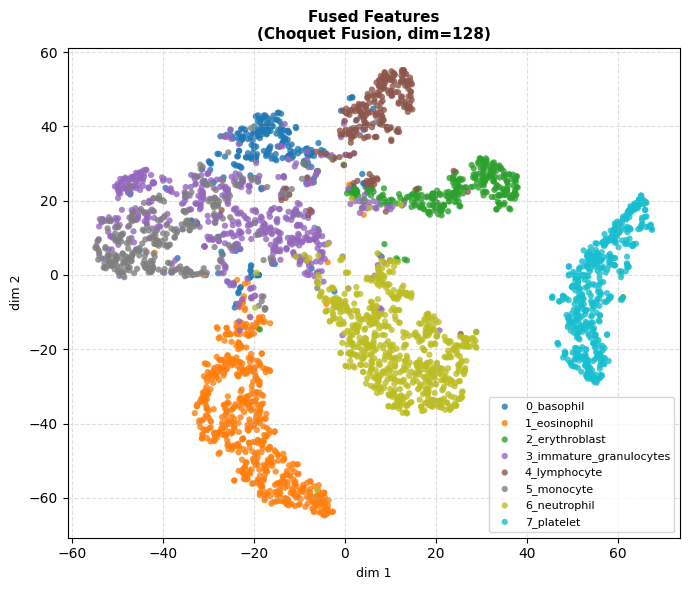

In [3]:
fig_local, ax1 = plt.subplots(figsize=(7, 6))
plot_tsne(local_f, labels, class_names, "Local Branch\n(Gabor-CNN, dim=64)", ax1)
plt.tight_layout()
plt.savefig("/kaggle/working/tsne_local_branch.png", dpi=150, bbox_inches='tight')
plt.show()

fig_global, ax2 = plt.subplots(figsize=(7, 6))
plot_tsne(global_f, labels, class_names, "Global Branch\n(Shifted-Window Attn, dim=256)", ax2)
plt.tight_layout()
plt.savefig("/kaggle/working/tsne_global_branch.png", dpi=150, bbox_inches='tight')
plt.show()

fig_fused, ax3 = plt.subplots(figsize=(7, 6))
plot_tsne(fused_f, labels, class_names, "Fused Features\n(Choquet Fusion, dim=128)", ax3)
plt.tight_layout()
plt.savefig("/kaggle/working/tsne_fused.png", dpi=150, bbox_inches='tight')
plt.show()

In [4]:
from IPython.display import FileLink, display
display(FileLink('/kaggle/working/tsne_local_branch.png'))
display(FileLink('/kaggle/working/tsne_global_branch.png'))
display(FileLink('/kaggle/working/tsne_fused.png'))

/kaggle/working/tsne_local_branch.png

/kaggle/working/tsne_global_branch.png

/kaggle/working/tsne_fused.png

Epoch 1 complete.
Epoch 2 complete.
Epoch 3 complete.
Epoch 4 complete.
Epoch 5 complete.


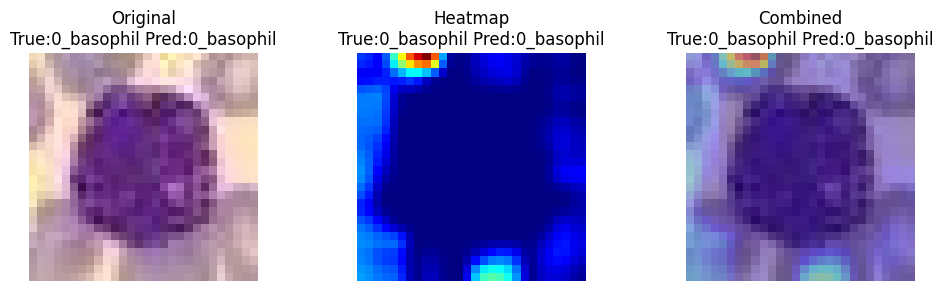

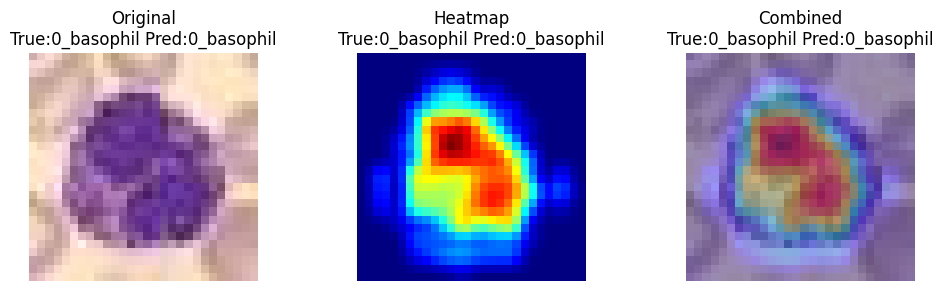

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0470588244497776..1.0000000238418578].


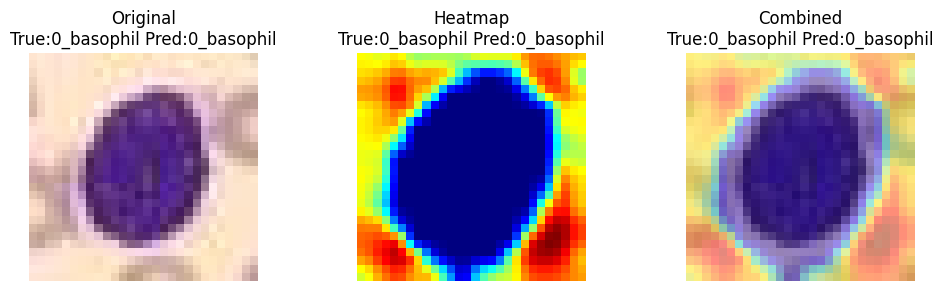

In [3]:
import os
import cv2
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 1. Config & Seed
# -------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR = "/kaggle/input/bloodmnist-2828-by-folder"
BATCH_SIZE = 32
IMG_SIZE = 28
EPOCHS = 5
LR = 1e-3
NUM_CLASSES = 8

# -------------------------------------------------------------
# 2. Components (Gabor, Local, Global Branches)
# -------------------------------------------------------------
class GaborLayer(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=11):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, padding=kernel_size//2, bias=False)
        self._init_gabor()

    def _init_gabor(self):
        for i in range(self.conv.weight.shape[0]):
            theta, sigma, lamda, gamma = np.random.uniform(0, np.pi), np.random.uniform(2, 5), \
                                         np.random.uniform(6, 10), 0.5
            ax = np.linspace(-(11//2), 11//2, 11)
            xx, yy = np.meshgrid(ax, ax)
            x = xx * np.cos(theta) + yy * np.sin(theta)
            y = -xx * np.sin(theta) + yy * np.cos(theta)
            gb = np.exp(-(x**2 + gamma**2 * y**2) / (2 * sigma**2)) * np.cos(2 * np.pi * x / lamda)
            for c in range(3): self.conv.weight.data[i, c] = torch.tensor(gb)

    def forward(self, x): return self.conv(x)

class LocalBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.gabor = GaborLayer(3, 16)
        self.features = nn.Sequential(
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU() # Target for Grad-CAM [B, 64, 14, 14]
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

    def forward(self, x):
        x = self.gabor(x)
        feat = self.features(x)
        out = self.pool(feat).view(feat.size(0), -1)
        return out, feat

class WindowMSA(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4):
        super().__init__()
        self.dim, self.ws, self.nh = dim, window_size, num_heads
        self.scale = (dim // num_heads) ** -0.5
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        B, H, W, C = x.shape
        x = x.view(B, H // self.ws, self.ws, W // self.ws, self.ws, C).permute(0, 1, 3, 2, 4, 5).reshape(-1, self.ws*self.ws, C)
        qkv = self.qkv(x).reshape(x.shape[0], x.shape[1], 3, self.nh, C // self.nh).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        out = (attn @ v).transpose(1, 2).reshape(-1, self.ws*self.ws, C)
        return self.proj(out).view(B, H // self.ws, W // self.ws, self.ws, self.ws, C).permute(0, 1, 3, 2, 4, 5).reshape(B, H, W, C)

class ShiftedWindowBlock(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4, shift_size=3):
        super().__init__()
        self.shift, self.ws = shift_size, window_size
        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowMSA(dim, window_size, num_heads)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, dim*4), nn.GELU(), nn.Linear(dim*4, dim))

    def forward(self, x):
        B, C, H, W = x.shape
        x = x.permute(0, 2, 3, 1)
        if self.shift > 0: x = torch.roll(x, shifts=(-self.shift, -self.shift), dims=(1, 2))
        x = x + self.attn(self.norm1(x))
        if self.shift > 0: x = torch.roll(x, shifts=(self.shift, self.shift), dims=(1, 2))
        x = x + self.mlp(self.norm2(x))
        return x.permute(0, 3, 1, 2)

class GlobalAttentionBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.stage1 = nn.Sequential(nn.Conv2d(3, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.stage2_conv = nn.Conv2d(64, 128, 3, padding=1)
        self.attn_block1 = ShiftedWindowBlock(dim=128, window_size=7, num_heads=4, shift_size=0)
        self.attn_block2 = ShiftedWindowBlock(dim=128, window_size=7, num_heads=4, shift_size=3)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.proj = nn.Sequential(nn.Linear(128, 256), nn.ReLU())

    def forward(self, x):
        x = self.stage2_conv(self.stage1(x))
        x = self.attn_block1(x)
        feat = self.attn_block2(x) # Target for Grad-CAM [B, 128, 14, 14]
        out = self.pool(feat).view(feat.size(0), -1)
        return self.proj(out), feat

# -------------------------------------------------------------
# 3. Choquet Fusion & Network
# -------------------------------------------------------------
class ChoquetFusion(nn.Module):
    def __init__(self, dim1, dim2, out_dim=128, p=2):
        super().__init__()
        self.fc1, self.fc2, self.p = nn.Linear(dim1, out_dim), nn.Linear(dim2, out_dim), p
    def forward(self, f1, f2):
        z1, z2 = self.fc1(f1), self.fc2(f2)
        d = torch.pow(torch.abs(z1 - z2), self.p).sum(dim=1, keepdim=True)
        return (z1 + z2) / (1.0 + d)

class DualBranchNet(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()
        self.local = LocalBranch()
        self.global_branch = GlobalAttentionBranch()
        self.fusion = ChoquetFusion(64, 256, 128, p=2)
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        f_l, feat_l = self.local(x)
        f_g, feat_g = self.global_branch(x)
        fused = self.fusion(f_l, f_g)
        return self.classifier(fused)

# -------------------------------------------------------------
# 4. Grad-CAM Class
# -------------------------------------------------------------
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.target_layer.register_forward_hook(self.forward_hook)
        self.target_layer.register_full_backward_hook(self.backward_hook)

    def forward_hook(self, module, input, output):
        self.activations = output

    def backward_hook(self, module, grad_in, grad_out):
        self.gradients = grad_out[0]

    def __call__(self, input_tensor, class_idx=None):
        self.model.eval()
        output = self.model(input_tensor)
        if class_idx is None: class_idx = torch.argmax(output, dim=1).item()
        
        self.model.zero_grad()
        one_hot = torch.zeros_like(output)
        one_hot[0][class_idx] = 1
        output.backward(gradient=one_hot, retain_graph=True)

        gradients = self.gradients.cpu().data.numpy()[0]
        activations = self.activations.cpu().data.numpy()[0]
        weights = np.mean(gradients, axis=(1, 2))
        
        cam = np.zeros(activations.shape[1:], dtype=np.float32)
        for i, w in enumerate(weights):
            cam += w * activations[i, :, :]
            
        cam = np.maximum(cam, 0)
        cam = cv2.resize(cam, (input_tensor.shape[3], input_tensor.shape[2]))
        if np.max(cam) > 0: cam = (cam - np.min(cam)) / (np.max(cam) - np.min(cam))
        return cam, class_idx

# -------------------------------------------------------------
# 5. Utilities & Grad-CAM Runner
# -------------------------------------------------------------
def unnormalize(tensor_img):
    img = tensor_img.permute(1, 2, 0).cpu().numpy()
    img = (img * 0.5) + 0.5 # Based on our Normalize(0.5, 0.5)
    return np.clip(img, 0, 1)

def plot_gradcam(model, target_layer, loader, class_names, num_images=3):
    model.eval()
    grad_cam = GradCAM(model, target_layer)
    images, labels = next(iter(loader))
    
    for i in range(min(num_images, len(images))):
        img_tensor = images[i].unsqueeze(0).to(device)
        cam, pred_idx = grad_cam(img_tensor)
        
        orig_img = unnormalize(images[i])
        heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0
        superimposed = heatmap * 0.4 + orig_img * 0.6

        plt.figure(figsize=(10, 3))
        for idx, (im, title) in enumerate(zip([orig_img, heatmap, superimposed], 
                                              ["Original", "Heatmap", "Combined"])):
            plt.subplot(1, 3, idx+1)
            plt.imshow(im)
            plt.title(f"{title}\nTrue:{class_names[labels[i]]} Pred:{class_names[pred_idx]}")
            plt.axis('off')
        plt.tight_layout()
        plt.show()

# -------------------------------------------------------------
# 6. Main execution logic
# -------------------------------------------------------------
if __name__ == "__main__":
    # Load Data
    val_test_transform = transforms.Compose([transforms.Resize((28, 28)), transforms.ToTensor(), transforms.Normalize((0.5,),(0.5,))])
    train_loader = DataLoader(datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=val_test_transform), batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(datasets.ImageFolder(os.path.join(DATA_DIR, "test"), transform=val_test_transform), batch_size=BATCH_SIZE, shuffle=False)
    CLASS_NAMES = datasets.ImageFolder(os.path.join(DATA_DIR, "train")).classes

    model = DualBranchNet(num_classes=NUM_CLASSES).to(device)
    optimizer = optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()

    # Simple Training Loop
    for epoch in range(EPOCHS):
        model.train()
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad(); loss = criterion(model(imgs), labels)
            loss.backward(); optimizer.step()
        print(f"Epoch {epoch+1} complete.")

    # Run Grad-CAM on Global Attention Branch features
    # Target: The last attention block before pooling
    target = model.global_branch.attn_block2
    plot_gradcam(model, target, test_loader, CLASS_NAMES)

Epoch 1/5 complete. Train Acc: 0.4308
Epoch 2/5 complete. Train Acc: 0.6022
Epoch 3/5 complete. Train Acc: 0.6591
Epoch 4/5 complete. Train Acc: 0.6787
Epoch 5/5 complete. Train Acc: 0.7071

>>> Searching correct predictions for all 8 classes...


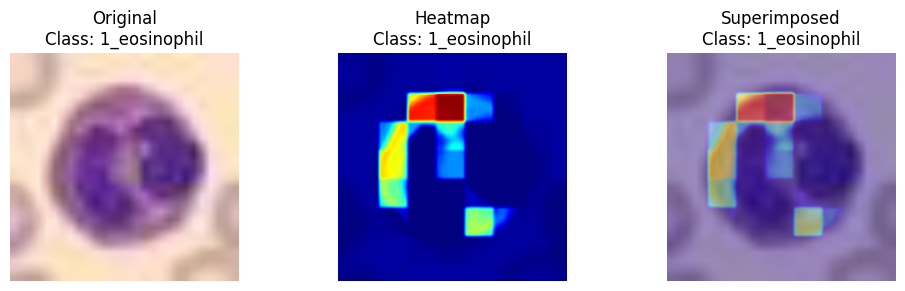

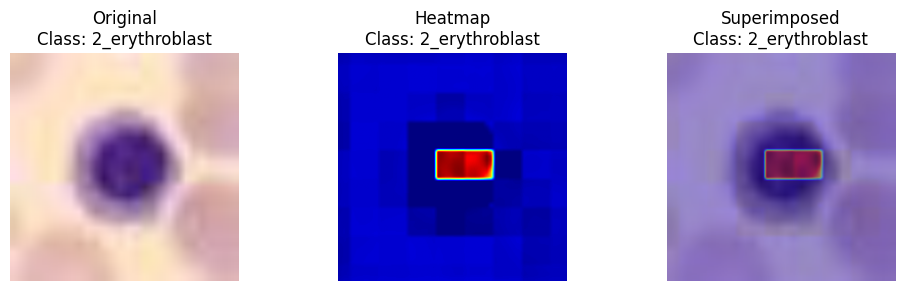

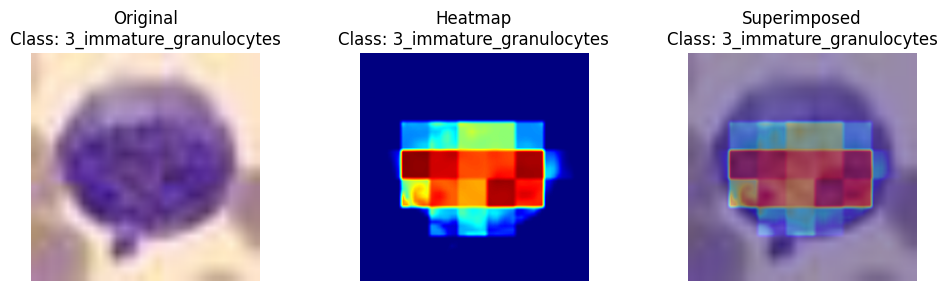

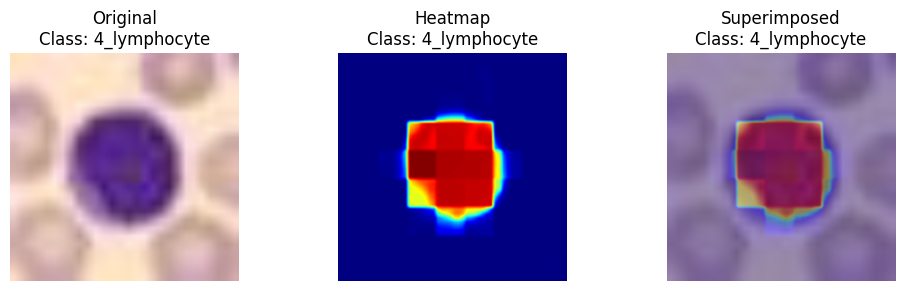

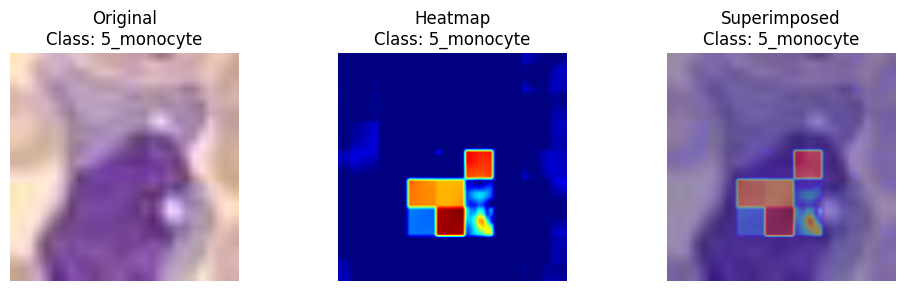

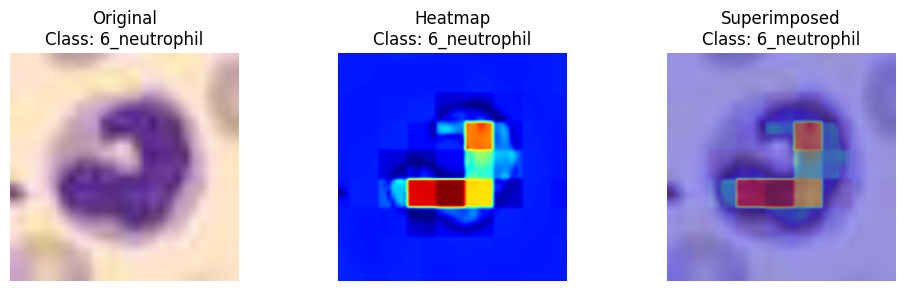

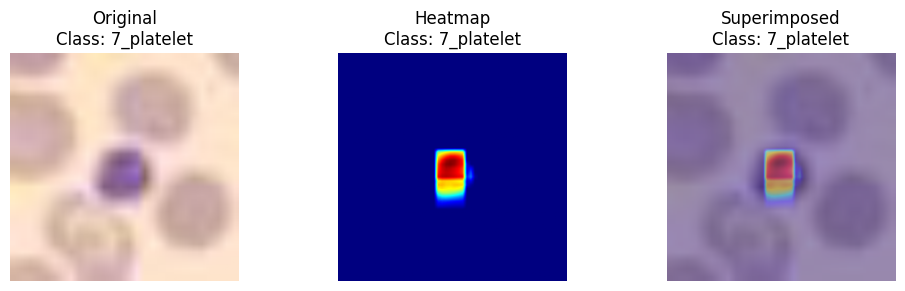

In [1]:
import os
import cv2
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 1. Config & Seed
# -------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR = "/kaggle/input/bloodmnist-2828-by-folder" 
IMG_SIZE = 224
BATCH_SIZE = 16 # Reduced batch size for high-res images
EPOCHS = 5
LR = 1e-4
NUM_CLASSES = 8

# -------------------------------------------------------------
# 2. Data Pipeline
# -------------------------------------------------------------
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

full_train_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=transform)
testA_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "test"), transform=transform)

n_val = int(len(full_train_ds) * 0.2)
n_train = len(full_train_ds) - n_val
train_ds, val_ds = random_split(full_train_ds, [n_train, n_val])

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
testA_loader = DataLoader(testA_ds, batch_size=BATCH_SIZE, shuffle=False)
CLASS_NAMES = full_train_ds.classes

# -------------------------------------------------------------
# 3. Model Architecture (Modified for Grad-CAM)
# -------------------------------------------------------------
class GaborLayer(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=11):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, padding=kernel_size//2, bias=False)
        self._init_gabor()
    def _init_gabor(self):
        for i in range(self.conv.weight.shape[0]):
            theta, sigma, lamda, gamma = np.random.uniform(0, np.pi), np.random.uniform(2, 5), np.random.uniform(6, 10), 0.5
            ax = np.linspace(-(11//2), 11//2, 11)
            xx, yy = np.meshgrid(ax, ax)
            x = xx * np.cos(theta) + yy * np.sin(theta)
            y = -xx * np.sin(theta) + yy * np.cos(theta)
            gb = np.exp(-(x**2 + gamma**2 * y**2) / (2 * sigma**2)) * np.cos(2 * np.pi * x / lamda)
            for c in range(3): self.conv.weight.data[i, c] = torch.tensor(gb)
    def forward(self, x): return self.conv(x)

class LocalBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.gabor = GaborLayer(3, 16)
        self.features = nn.Sequential(
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU()
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
    def forward(self, x):
        feat = self.features(self.gabor(x))
        return self.pool(feat).view(feat.size(0), -1), feat

class WindowMSA(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4):
        super().__init__()
        self.dim, self.ws, self.nh = dim, window_size, num_heads
        self.scale = (dim // num_heads) ** -0.5
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)
    def forward(self, x):
        B, H, W, C = x.shape
        x = x.view(B, H // self.ws, self.ws, W // self.ws, self.ws, C).permute(0, 1, 3, 2, 4, 5).reshape(-1, self.ws*self.ws, C)
        qkv = self.qkv(x).reshape(x.shape[0], x.shape[1], 3, self.nh, C // self.nh).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = (attn.softmax(dim=-1) @ v).transpose(1, 2).reshape(-1, self.ws*self.ws, C)
        return self.proj(attn).view(B, H // self.ws, W // self.ws, self.ws, self.ws, C).permute(0, 1, 3, 2, 4, 5).reshape(B, H, W, C)

class ShiftedWindowBlock(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4, shift_size=3):
        super().__init__()
        self.shift, self.ws = shift_size, window_size
        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowMSA(dim, window_size, num_heads)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, dim*4), nn.GELU(), nn.Linear(dim*4, dim))
    def forward(self, x):
        x = x.permute(0, 2, 3, 1)
        if self.shift > 0: x = torch.roll(x, shifts=(-self.shift, -self.shift), dims=(1, 2))
        x = x + self.attn(self.norm1(x))
        if self.shift > 0: x = torch.roll(x, shifts=(self.shift, self.shift), dims=(1, 2))
        return (x + self.mlp(self.norm2(x))).permute(0, 3, 1, 2)

class GlobalAttentionBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.stage1 = nn.Sequential(nn.Conv2d(3, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.stage2 = nn.Sequential(nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.attn = ShiftedWindowBlock(128, 7, 4, 3) 
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.proj = nn.Sequential(nn.Linear(128, 256), nn.ReLU())
    def forward(self, x):
        feat = self.attn(self.stage2(self.stage1(x)))
        out = self.pool(feat).view(feat.size(0), -1)
        return self.proj(out), feat

class ChoquetFusion(nn.Module):
    def __init__(self, dim1, dim2, out_dim=128, p=2):
        super().__init__()
        self.fc1, self.fc2, self.p = nn.Linear(dim1, out_dim), nn.Linear(dim2, out_dim), p
    def forward(self, f1, f2):
        z1, z2 = self.fc1(f1), self.fc2(f2)
        d = torch.pow(torch.abs(z1 - z2), self.p).sum(dim=1, keepdim=True)
        return (z1 + z2) / (1.0 + d)

class DualBranchNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.local = LocalBranch()
        self.global_branch = GlobalAttentionBranch()
        self.fusion = ChoquetFusion(128, 256, 128, p=2)
        self.classifier = nn.Linear(128, NUM_CLASSES)
    def forward(self, x):
        f_l, _ = self.local(x)
        f_g, _ = self.global_branch(x)
        return self.classifier(self.fusion(f_l, f_g))

# -------------------------------------------------------------
# 4. Grad-CAM Class
# -------------------------------------------------------------
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.target_layer.register_forward_hook(self.forward_hook)
        self.target_layer.register_full_backward_hook(self.backward_hook)
    def forward_hook(self, m, i, o): self.activations = o
    def backward_hook(self, m, gi, go): self.gradients = go[0]
    def __call__(self, x, idx=None):
        self.model.eval()
        out = self.model(x)
        if idx is None: idx = torch.argmax(out, 1).item()
        self.model.zero_grad()
        one_hot = torch.zeros_like(out); one_hot[0][idx] = 1
        out.backward(gradient=one_hot, retain_graph=True)
        grads = self.gradients.cpu().data.numpy()[0]
        acts = self.activations.cpu().data.numpy()[0]
        weights = np.mean(grads, axis=(1, 2))
        cam = np.zeros(acts.shape[1:], dtype=np.float32)
        for i, w in enumerate(weights): cam += w * acts[i, :, :]
        cam = np.maximum(cam, 0)
        cam = cv2.resize(cam, (x.shape[3], x.shape[2]))
        if np.max(cam) > 0: cam = (cam - cam.min()) / (cam.max() - cam.min())
        return cam, idx

def plot_per_class_gradcam(model, target_layer, loader, class_names):
    gcam = GradCAM(model, target_layer)
    visualized = set()
    total = len(class_names)
    print(f"\n>>> Searching correct predictions for all {total} classes...")
    
    for imgs, lbls in loader:
        if len(visualized) == total: break
        imgs, lbls = imgs.to(device), lbls.to(device)
        out = model(imgs)
        preds = out.argmax(1)
        
        for i in range(len(lbls)):
            t_idx, p_idx = lbls[i].item(), preds[i].item()
            if t_idx == p_idx and t_idx not in visualized:
                visualized.add(t_idx)
                img_t = imgs[i].unsqueeze(0).requires_grad_(True)
                cam, _ = gcam(img_t, idx=t_idx)
                orig = (imgs[i].permute(1,2,0).cpu().numpy() * 0.5 + 0.5).clip(0, 1)
                heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
                heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0
                res = heatmap * 0.4 + orig * 0.6
                
                plt.figure(figsize=(10, 3))
                for j, (im, t) in enumerate(zip([orig, heatmap, res], ["Original", "Heatmap", "Superimposed"])):
                    plt.subplot(1, 3, j+1); plt.imshow(im); plt.axis('off')
                    plt.title(f"{t}\nClass: {class_names[t_idx]}")
                plt.tight_layout(); plt.show()

# -------------------------------------------------------------
# 5. Execution Logic
# -------------------------------------------------------------
if __name__ == "__main__":
    model = DualBranchNet().to(device)
    optimizer = optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        t_acc = []
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad(); out = model(imgs)
            loss = criterion(out, labels); loss.backward(); optimizer.step()
            t_acc.append(accuracy_score(labels.cpu(), out.argmax(1).cpu()))
        print(f"Epoch {epoch}/{EPOCHS} complete. Train Acc: {np.mean(t_acc):.4f}")

    # Run Per-Class Grad-CAM
    plot_per_class_gradcam(model, model.global_branch.attn, testA_loader, CLASS_NAMES)